# Reproducing *Isolation Forest* (Liu, Ting & Zhou, ICDM 2008)

This notebook reproduces the main experiment of the paper: **Table 3**, the AUC and processing time of iForest on 12 benchmark datasets, with LOF as a baseline. It also reproduces two supporting results: the effect of the sub-sampling size ψ (Figure 6) and the Mulcross sub-sampling example (Section 3).

**Implementation.** iForest comes from `sklearn.ensemble.IsolationForest`, which follows Algorithms 1–3 of the paper. With `max_samples=ψ` it draws ψ points without replacement per tree, grows each tree to height ⌈log₂ ψ⌉, and adds c(size) at leaves holding several points. `score_samples` returns −s(x, ψ), so we negate it to obtain the paper's anomaly score. LOF comes from `sklearn.neighbors.LocalOutlierFactor`.

**Not reproduced:** ORCA (no maintained Python implementation) and the Random Forest proximity baseline.

## 1. Setup and parameters

In [1]:
import os, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import special_ortho_group
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import roc_auc_score
import sklearn

# ---- parameters (paper defaults) ----
PSI = 256        # sub-sampling size ψ (paper: 256)
T = 100          # number of trees t (paper: 100)
N_RUNS = 10      # repeated runs with different seeds (paper: not stated, single value reported)
LOF_K = 10       # LOF neighbourhood size (paper: k = 10)
N_JOBS = 1       # single-threaded, as in the paper
DATA_DIR = "data"

print("scikit-learn", sklearn.__version__, "| numpy", np.__version__)

scikit-learn 1.2.1 | numpy 1.23.5


## 2. Data

Eleven real datasets are downloaded once from public GitHub mirrors of the ODDS anomaly-detection benchmark (ADBench's *Classical* folder, and the XGBOD repository for Arrhythmia). These versions keep only continuous attributes and mark the paper's anomaly classes with `y = 1`, matching the paper's preprocessing.

In [2]:
ADBENCH = "https://raw.githubusercontent.com/Minqi824/ADBench/main/adbench/datasets/Classical/"
SOURCES = {
    "http.npz":        ADBENCH + "16_http.npz",
    "cover.npz":       ADBENCH + "10_cover.npz",
    "smtp.npz":        ADBENCH + "34_smtp.npz",
    "shuttle.npz":     ADBENCH + "32_shuttle.npz",
    "mammography.npz": ADBENCH + "23_mammography.npz",
    "annthyroid.npz":  ADBENCH + "2_annthyroid.npz",
    "satellite.npz":   ADBENCH + "30_satellite.npz",
    "pima.npz":        ADBENCH + "29_Pima.npz",
    "breastw.npz":     ADBENCH + "4_breastw.npz",
    "ionosphere.npz":  ADBENCH + "18_Ionosphere.npz",
    "arrhythmia.mat":  "https://raw.githubusercontent.com/yzhao062/XGBOD/master/datasets/arrhythmia.mat",
}
os.makedirs(DATA_DIR, exist_ok=True)
for fname, url in SOURCES.items():
    target = os.path.join(DATA_DIR, fname)
    npz_target = os.path.join(DATA_DIR, fname.replace(".mat", ".npz"))
    if os.path.exists(npz_target):
        continue
    urllib.request.urlretrieve(url, target)
    if fname.endswith(".mat"):                     # convert Arrhythmia to the same .npz format
        m = loadmat(target)
        np.savez_compressed(npz_target, X=m["X"].astype(float), y=m["y"].ravel().astype(int))
        os.remove(target)
print(sorted(os.listdir(DATA_DIR)))

['annthyroid.npz', 'arrhythmia.npz', 'breastw.npz', 'cover.npz', 'http.npz', 'ionosphere.npz', 'mammography.npz', 'pima.npz', 'satellite.npz', 'shuttle.npz', 'smtp.npz']


**Mulcross** is synthetic and its original generator (Rocke & Woodruff, 1996) is not available, so it is re-created from the paper's description: 262,144 points in 4 dimensions, 10% anomalies in 2 clusters, distance factor 2, with anomaly clusters at least as dense as the normal cluster. Assumptions made here:

* normal points ~ N(0, I₄);
* each anomaly cluster is Gaussian, centred `distance_factor · √d` from the origin (2 standard deviations in every coordinate) in a random direction;
* the anomaly-cluster spread is chosen so its peak density equals that of the normal cluster.

In [3]:
def make_mulcross(n=262144, d=4, contamination=0.10, distance_factor=2.0, n_clusters=2, random_state=0):
    rng = np.random.default_rng(random_state)
    n_anom = int(round(n * contamination)); n_norm = n - n_anom
    per = np.full(n_clusters, n_anom // n_clusters); per[: n_anom % n_clusters] += 1
    X_norm = rng.standard_normal((n_norm, d))
    spread = (per[0] / n_norm) ** (1.0 / d)                 # equal peak density
    dirs = special_ortho_group.rvs(d, random_state=random_state)[:n_clusters]
    clusters = [distance_factor * np.sqrt(d) * dirs[k] + spread * rng.standard_normal((per[k], d))
                for k in range(n_clusters)]
    X = np.vstack([X_norm, *clusters])
    y = np.r_[np.zeros(n_norm, int), np.ones(n_anom, int)]
    perm = rng.permutation(n)
    return X[perm], y[perm]

In [4]:
# Table 2 of the paper: name -> (file, n, d, anomaly %)
TABLE2 = {
    "Http":        ("http.npz",        567497, 3,   0.4),
    "ForestCover": ("cover.npz",       286048, 10,  0.9),
    "Mulcross":    (None,              262144, 4,   10.0),
    "Smtp":        ("smtp.npz",        95156,  3,   0.03),
    "Shuttle":     ("shuttle.npz",     49097,  9,   7.0),
    "Mammography": ("mammography.npz", 11183,  6,   2.0),
    "Annthyroid":  ("annthyroid.npz",  6832,   6,   7.0),
    "Satellite":   ("satellite.npz",   6435,   36,  32.0),
    "Pima":        ("pima.npz",        768,    8,   35.0),
    "Breastw":     ("breastw.npz",     683,    9,   35.0),
    "Arrhythmia":  ("arrhythmia.npz",  452,    274, 15.0),
    "Ionosphere":  ("ionosphere.npz",  351,    32,  36.0),
}

def load(name):
    if name == "Mulcross":
        return make_mulcross()
    d = np.load(os.path.join(DATA_DIR, TABLE2[name][0]))
    return d["X"].astype(float), d["y"].astype(int).ravel()

DATA = {name: load(name) for name in TABLE2}

check = pd.DataFrame([
    {"dataset": name, "n (paper)": n_p, "n (ours)": DATA[name][0].shape[0],
     "d (paper)": d_p, "d (ours)": DATA[name][0].shape[1],
     "anomaly % (paper)": a_p, "anomaly % (ours)": round(100 * DATA[name][1].mean(), 2)}
    for name, (_, n_p, d_p, a_p) in TABLE2.items()]).set_index("dataset")
check

,n (paper),n (ours),d (paper),d (ours),anomaly % (paper),anomaly % (ours)
dataset,,,,,,
Http,567497,567498,3,3,0.40,0.39
ForestCover,286048,286048,10,10,0.90,0.96
Mulcross,262144,262144,4,4,10.00,10.00
Smtp,95156,95156,3,3,0.03,0.03
Shuttle,49097,49097,9,9,7.00,7.15
Mammography,11183,11183,6,6,2.00,2.32
Annthyroid,6832,7200,6,6,7.00,7.42
Satellite,6435,6435,36,36,32.00,31.64
Pima,768,768,8,8,35.00,34.90


All datasets match Table 2 except **Annthyroid**, which has 7,200 instances instead of 6,832 (the full UCI thyroid set; the paper's subset is not documented), and **Http**, which has one extra instance. The ODDS versions of Http and Smtp are also log-transformed, which may differ from the paper's copy.

## 3. Main experiment: Table 3 (iForest AUC and processing time)

In [5]:
# Values reported in Table 3 of the paper (NaN = not reported)
nan = np.nan
PAPER = pd.DataFrame({
    #               iF AUC  ORCA  LOF   RF     iF train iF eval  iF total  LOF time
    "Http":        [1.00, 0.36, nan,  nan,  0.25,  15.33, 15.58, nan],
    "ForestCover": [0.88, 0.83, nan,  nan,  0.76,  15.57, 16.33, nan],
    "Mulcross":    [0.97, 0.33, nan,  nan,  0.26,  12.26, 12.52, nan],
    "Smtp":        [0.88, 0.80, nan,  nan,  0.14,  2.58,  2.72,  nan],
    "Shuttle":     [1.00, 0.60, 0.55, nan,  0.30,  2.83,  3.13,  7489.74],
    "Mammography": [0.86, 0.77, 0.67, nan,  0.16,  0.50,  0.66,  14647.00],
    "Annthyroid":  [0.82, 0.68, 0.72, nan,  0.15,  0.36,  0.51,  72.02],
    "Satellite":   [0.71, 0.65, 0.52, nan,  0.46,  1.17,  1.63,  217.39],
    "Pima":        [0.67, 0.71, 0.49, 0.65, 0.17,  0.11,  0.28,  1.14],
    "Breastw":     [0.99, 0.98, 0.37, 0.97, 0.17,  0.11,  0.28,  1.77],
    "Arrhythmia":  [0.80, 0.78, 0.73, 0.60, 2.12,  0.86,  2.98,  6.35],
    "Ionosphere":  [0.85, 0.92, 0.89, 0.85, 0.33,  0.15,  0.48,  0.64],
}, index=["iForest AUC", "ORCA AUC", "LOF AUC", "RF AUC",
          "iForest train (s)", "iForest eval (s)", "iForest total (s)", "LOF time (s)"]).T
PAPER

,iForest AUC,ORCA AUC,LOF AUC,RF AUC,iForest train (s),iForest eval (s),iForest total (s),LOF time (s)
Http,1.00,0.36,NaN,NaN,0.25,15.33,15.58,NaN
ForestCover,0.88,0.83,NaN,NaN,0.76,15.57,16.33,NaN
Mulcross,0.97,0.33,NaN,NaN,0.26,12.26,12.52,NaN
Smtp,0.88,0.80,NaN,NaN,0.14,2.58,2.72,NaN
Shuttle,1.00,0.60,0.55,NaN,0.30,2.83,3.13,7489.74
Mammography,0.86,0.77,0.67,NaN,0.16,0.50,0.66,14647.00
Annthyroid,0.82,0.68,0.72,NaN,0.15,0.36,0.51,72.02
Satellite,0.71,0.65,0.52,NaN,0.46,1.17,1.63,217.39
Pima,0.67,0.71,0.49,0.65,0.17,0.11,0.28,1.14
Breastw,0.99,0.98,0.37,0.97,0.17,0.11,0.28,1.77


As in the paper, each forest is trained on the whole dataset without labels (the default ψ = 256 sub-sample is drawn inside `fit`), every instance is then scored, and AUC is computed against the anomaly labels. The paper reports one number per dataset; here the experiment is repeated with `N_RUNS` seeds and the mean ± standard deviation is reported.

In [6]:
rows = []
for name, (X, y) in DATA.items():
    for seed in range(N_RUNS):
        model = IsolationForest(n_estimators=T, max_samples=PSI, random_state=seed, n_jobs=N_JOBS)
        t0 = time.perf_counter(); model.fit(X); t1 = time.perf_counter()
        s = -model.score_samples(X)                     # s(x, ψ): higher = more anomalous
        t2 = time.perf_counter()
        rows.append({"dataset": name, "seed": seed, "auc": roc_auc_score(y, s),
                     "train": t1 - t0, "eval": t2 - t1})
    print(f"{name:12s} done")
iforest_runs = pd.DataFrame(rows)

Http         done
ForestCover  done
Mulcross     done
Smtp         done
Shuttle      done
Mammography  done
Annthyroid   done
Satellite    done
Pima         done
Breastw      done
Arrhythmia   done
Ionosphere   done


### LOF baseline
LOF (k = 10) is run on the eight datasets for which the paper reports LOF results. LOF is deterministic, so a single run is enough.

In [7]:
lof_rows = []
for name in ["Shuttle", "Mammography", "Annthyroid", "Satellite", "Pima", "Breastw", "Arrhythmia", "Ionosphere"]:
    X, y = DATA[name]
    t0 = time.perf_counter()
    lof = LocalOutlierFactor(n_neighbors=LOF_K, n_jobs=N_JOBS).fit(X)
    s = -lof.negative_outlier_factor_                  # higher = more anomalous
    lof_rows.append({"dataset": name, "LOF AUC (ours)": roc_auc_score(y, s),
                     "LOF time (ours, s)": time.perf_counter() - t0})
lof_res = pd.DataFrame(lof_rows).set_index("dataset")
lof_res.round(3)

,LOF AUC (ours),"LOF time (ours, s)"
dataset,,
Shuttle,0.552,10.785
Mammography,0.671,0.899
Annthyroid,0.724,0.297
Satellite,0.522,0.521
Pima,0.494,0.025
Breastw,0.421,0.034
Arrhythmia,0.732,0.148
Ionosphere,0.899,0.131


### Comparison with the paper

In [8]:
agg = iforest_runs.groupby("dataset", sort=False).agg(
    auc_mean=("auc", "mean"), auc_std=("auc", "std"),
    train=("train", "mean"), eval=("eval", "mean"))
agg["total"] = agg["train"] + agg["eval"]

cmp = pd.DataFrame({
    "iForest AUC (paper)": PAPER["iForest AUC"],
    "iForest AUC (ours)":  agg["auc_mean"].round(3).astype(str) + " ± " + agg["auc_std"].round(3).astype(str),
    "Δ AUC":               (agg["auc_mean"] - PAPER["iForest AUC"]).round(3),
    "LOF AUC (paper)":     PAPER["LOF AUC"],
    "LOF AUC (ours)":      lof_res["LOF AUC (ours)"].round(3),
    "iForest total s (paper)": PAPER["iForest total (s)"],
    "iForest train s (ours)":  agg["train"].round(2),
    "iForest eval s (ours)":   agg["eval"].round(2),
    "iForest total s (ours)":  agg["total"].round(2),
    "LOF s (paper)":       PAPER["LOF time (s)"],
    "LOF s (ours)":        lof_res["LOF time (ours, s)"].round(2),
}).loc[list(TABLE2)]
cmp

,iForest AUC (paper),iForest AUC (ours),Δ AUC,LOF AUC (paper),LOF AUC (ours),iForest total s (paper),iForest train s (ours),iForest eval s (ours),iForest total s (ours),LOF s (paper),LOF s (ours)
Http,1.00,1.0 ± 0.0,-0.000,NaN,NaN,15.58,1.78,39.08,40.85,NaN,NaN
ForestCover,0.88,0.877 ± 0.037,-0.003,NaN,NaN,16.33,1.35,20.30,21.65,NaN,NaN
Mulcross,0.97,0.95 ± 0.009,-0.020,NaN,NaN,12.52,1.21,20.38,21.58,NaN,NaN
Smtp,0.88,0.904 ± 0.006,0.024,NaN,NaN,2.72,0.83,6.43,7.27,NaN,NaN
Shuttle,1.00,0.997 ± 0.001,-0.003,0.55,0.552,3.13,0.81,3.77,4.58,7489.74,10.78
Mammography,0.86,0.861 ± 0.008,0.001,0.67,0.671,0.66,0.53,0.76,1.29,14647.00,0.90
Annthyroid,0.82,0.818 ± 0.017,-0.002,0.72,0.724,0.51,0.49,0.52,1.01,72.02,0.30
Satellite,0.71,0.701 ± 0.02,-0.009,0.52,0.522,1.63,0.51,0.65,1.15,217.39,0.52
Pima,0.67,0.671 ± 0.007,0.001,0.49,0.494,0.28,0.48,0.18,0.66,1.14,0.02
Breastw,0.99,0.987 ± 0.001,-0.003,0.37,0.421,0.28,0.48,0.17,0.65,1.77,0.03


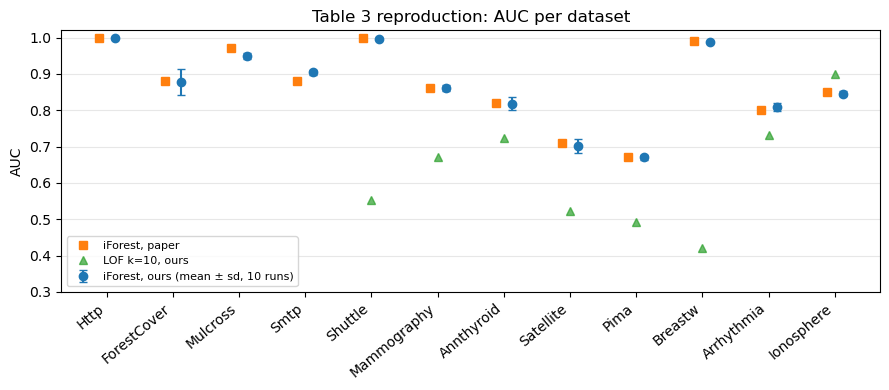

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
names = list(TABLE2)
x = np.arange(len(names))
ax.errorbar(x + 0.12, agg.loc[names, "auc_mean"], yerr=agg.loc[names, "auc_std"],
            fmt="o", capsize=3, label=f"iForest, ours (mean ± sd, {N_RUNS} runs)")
ax.plot(x - 0.12, PAPER.loc[names, "iForest AUC"], "s", label="iForest, paper")
ax.plot(x, lof_res.reindex(names)["LOF AUC (ours)"], "^", alpha=.7, label="LOF k=10, ours")
ax.set_xticks(x, names, rotation=40, ha="right"); ax.set_ylabel("AUC"); ax.set_ylim(0.3, 1.02)
ax.grid(axis="y", alpha=.3); ax.legend(loc="lower left", fontsize=8)
ax.set_title("Table 3 reproduction: AUC per dataset")
plt.tight_layout(); plt.show()

## 4. Supporting experiment: effect of sub-sampling size ψ (Figure 6)

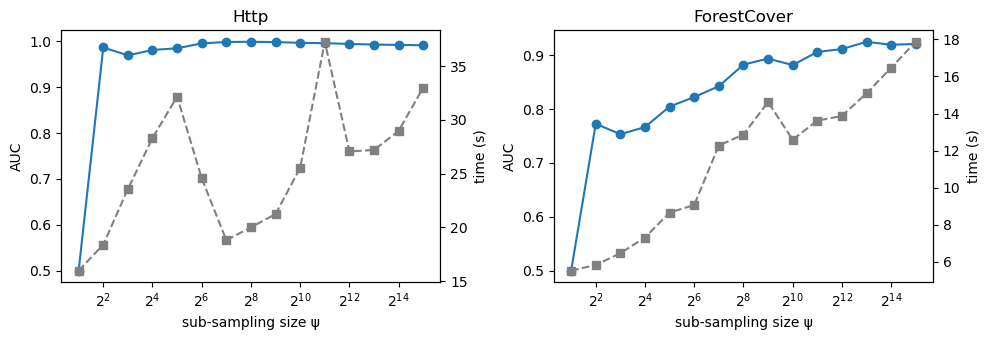

auc    time
dataset     psi                 
ForestCover 2      0.500   5.531
            4      0.773   5.838
            8      0.753   6.472
            16     0.767   7.318
            32     0.805   8.662
            64     0.822   9.071
            128    0.842  12.279
            256    0.882  12.870
            512    0.894  14.621
            1024   0.882  12.591
            2048   0.906  13.621
            4096   0.911  13.870
            8192   0.925  15.091
            16384  0.919  16.471
            32768  0.921  17.871
Http        2      0.500  15.980
            4      0.987  18.398
            8      0.970  23.560
            16     0.981  28.313
            32     0.985  32.155
            64     0.996  24.573
            128    0.999  18.822
            256    0.999  20.010
            512    0.999  21.244
            1024   0.997  25.541
            2048   0.996  37.257
            4096   0.995  27.068
            8192   0.993  27.199
            16384  0.992  28.968
            32768  0.992  33.007

In [10]:
PSIS = [2 ** k for k in range(1, 16)]       # 2, 4, ..., 32768 as in the paper
sweep = []
for name in ["Http", "ForestCover"]:
    X, y = DATA[name]
    for psi in PSIS:
        for seed in range(3):
            m = IsolationForest(n_estimators=T, max_samples=psi, random_state=seed, n_jobs=N_JOBS)
            t0 = time.perf_counter(); s = -m.fit(X).score_samples(X); dt = time.perf_counter() - t0
            sweep.append({"dataset": name, "psi": psi, "seed": seed, "auc": roc_auc_score(y, s), "time": dt})
sweep = pd.DataFrame(sweep).groupby(["dataset", "psi"]).mean(numeric_only=True).drop(columns="seed")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, name in zip(axes, ["Http", "ForestCover"]):
    d = sweep.loc[name]
    ax.plot(d.index, d["auc"], "o-", label="AUC"); ax.set_xscale("log", base=2)
    ax.set_xlabel("sub-sampling size ψ"); ax.set_ylabel("AUC"); ax.set_title(name)
    ax2 = ax.twinx(); ax2.plot(d.index, d["time"], "s--", color="gray", label="time (s)"); ax2.set_ylabel("time (s)")
plt.tight_layout(); plt.show()
sweep.round(3)

## 5. Supporting experiment: sub-sampling against swamping and masking (Section 3)
The paper draws 4,096 Mulcross points and reports AUC 0.67 when the whole sample is used per tree versus 0.91 with ψ = 128.

In [11]:
Xm, ym = make_mulcross(n=4096, random_state=1)
res = {}
for psi in [4096, 128]:
    aucs = [roc_auc_score(ym, -IsolationForest(n_estimators=T, max_samples=psi, random_state=s).fit(Xm).score_samples(Xm))
            for s in range(N_RUNS)]
    res[f"ψ = {psi}"] = f"{np.mean(aucs):.3f} ± {np.std(aucs):.3f}"
pd.Series(res, name="AUC (ours)").to_frame().assign(**{"AUC (paper)": [0.67, 0.91]})

,AUC (ours),AUC (paper)
ψ = 4096,0.895 ± 0.008,0.67
ψ = 128,0.960 ± 0.010,0.91


## 6. Parameters used

| Parameter | Value | Source |
|---|---|---|
| Number of trees t (`n_estimators`) | 100 | paper default |
| Sub-sampling size ψ (`max_samples`) | 256 (Fig. 6 sweep: 2 … 32768) | paper default |
| Tree height limit | ⌈log₂ ψ⌉ = 8 | paper, set automatically by scikit-learn |
| Features per split (`max_features`) | 1.0 (one random attribute per split) | paper |
| `contamination` | `'auto'` (unused; AUC uses the raw scores) | — |
| Repeated runs | 10 seeds (0–9) | ours; paper reports single values |
| LOF neighbours k | 10 | paper |
| Threads | 1 (`n_jobs=1`) | paper ran single-threaded |
| Mulcross | n = 262,144, d = 4, 10% anomalies, 2 clusters, distance factor 2 | paper; generator re-created |